# Proyecto Integrador M1

InsightReach es una empresa de marketing digital especializada en campañas personalizadas para negocios locales. Con el crecimiento de su base de clientes y la expansión a nuevos mercados, la empresa busca optimizar su estrategia de segmentación para mejorar la efectividad de sus campañas.

Para ello, se ha diseñado un reto técnico dirigido a candidatos para el rol de Científico de Datos Junior, cuyo objetivo es demostrar su capacidad para integrar múltiples fuentes de datos, analizarlas y generar insights accionables.

## Avance 1

### Cargar y explorar la base de datos de los clientes

In [ ]:
#Primero importamos las librerías necesarias
import numpy as np
import pandas as pd

In [ ]:
#Cargar una base de datos de clientes
url = "https://raw.githubusercontent.com/pachecobravo/ProyectoM1_Christian_Pacheco/refs/heads/main/Documentaci%C3%B3n/base_datos_restaurantes_USA_v2.csv"
df_restaurantes = pd.read_csv(url)

### Exploración inicial

In [ ]:
#Aquí vemos las primeras 5 filas del dataset y cómo están organizados los registros.
print(df_restaurantes.head())

In [ ]:
#Ver el tamaño de la base de datos
df_restaurantes.shape
#Tenemos 30000 filas y 17 columnas, por lo que es una base de datos grande.

In [ ]:
#Veremos el tamaño, tipos de datos y posibles problemas.
df_restaurantes.info()
#Detectamos que existen valores nulos en algunas columnas, 
#por lo que debemos tratarlos antes de continuar con el análisis.
#edad: 101 nulos
#promedio_gasto_comida: 145
#preferencias_alimenticias: 1.403
#telefono_contacto: 15.166
#correo_electronico: 15.072

In [ ]:
#Vemos los nombres de las columnas para tener una idea de qué información tenemos.
df_restaurantes.columns
#Tenemos 17 columnas, que son las siguientes:

In [ ]:
#Estadísticas descriptivas de las columnas numéricas
df_restaurantes.describe()
#Aqui vemos dos variables que tienen valores negativos, que son edad y frecuencia_visita, por lo que debemos tratarlas antes de continuar con el análisis.

#Además vemos el valor máxmimo de edad que es 300, lo cual es un valor muy alto y poco probable, por lo que debemos tratarlo antes de continuar con el análisis.

In [ ]:
#Verificamos los valores negativos en la columna edad
df_restaurantes[df_restaurantes['edad'] < 0]
#Tenemos 97 valores negativos en la columna edad.

In [ ]:
#Verificamos los valores que superan los 100 años en la columna edad
df_restaurantes[df_restaurantes['edad'] > 100]
#Tenemos 110 valores que superan los 100 años en la columna edad, lo cual es un valor muy alto y poco probable.

In [ ]:
#Vemos los tipos de datos de cada columna para tener una idea de qué información tenemos.
df_restaurantes.dtypes
#Aquí llama la atención la edad que es de tipo float, por ahora lo dejamos así

##### Observaciones de la exploración inicial
- La base tiene 30.000 filas y 17 columnas (3 numéricas (int), 2 decimales de tipo float, 12 de texto(str)).
- `id_persona` es un identificador; sus estadísticas no tienen interpretación.
- En `edad` el mínimo es -5 y el máximo 300, y en `frecuencia_visita` el mínimo es -3. Son valores
  que parecen imposibles y se revisarán en la limpieza.
- `ingresos_mensuales` va de 800 a 17.999 y `promedio_gasto_comida` de 0 a 149,97.
- `info()` muestra columnas con menos de 30.000 valores no nulos; se tratarán en la limpieza.

### Limpieza de datos, identificar valores nulos, duplicados y errores.

In [ ]:
#Vemos la cantidad de valores nulos en cada columna para tener una idea de qué información tenemos.
df_restaurantes.isnull().sum()
#Tenemos 5 columnas con valores nulos, que son las siguientes:
#edad: 101 nulos
#promedio_gasto_comida: 145 nulos
#preferencias_alimenticias: 1403 nulos
#telefono_contacto: 15166 nulos
#correo_electronico: 15072 nulos

In [ ]:
#Verificamos si existen valores duplicados en el dataframe
df_restaurantes.duplicated().sum()
#No hay filas duplicadas

In [ ]:
#Esta columna al tener valores atípicos, usamos la mediana.
#Reemplazamos los valores outliers en la columna edad por nan, para poder tratarlos después.
df_restaurantes['edad'] = df_restaurantes['edad'].replace([-5, 300], np.nan)

In [ ]:
#Antes de rellenar debemos calcular la edad mediana por género, para poder rellenar los valores nulos de manera más precisa.
df_restaurantes.groupby('genero')['edad'].median()
#Tenemos la misma mediana en ambos géneros

In [ ]:
#Ahora rellenamos los valores nulos de la columna edad con la mediana de cada género.
df_restaurantes['edad'] = df_restaurantes.groupby('genero')['edad'].transform(
    lambda x: x.fillna(x.median())
)

#Verificamos si quedó bien la limpieza
df_restaurantes['edad'].describe()
#Ya no existe valores erróneos e la columna edad

In [ ]:
#Ahora vamos a verificar cual es la mediana en la columna de frecuencia_visita, de acuedo a cada género
df_restaurantes[df_restaurantes['frecuencia_visita'] >= 0].groupby('genero')['frecuencia_visita'].median()
#Vemos que es la misma para cada uno de 4

In [ ]:
#Ahora reemplazamos los valores negativos en la columna frecuencia_visita por la mediana de cada género, que es 4.
df_restaurantes['frecuencia_visita'] = df_restaurantes[
    'frecuencia_visita'
].replace(-3, 4)

#Verificamos los los valores menores a 0
df_restaurantes['frecuencia_visita'].value_counts().sort_index()
#Vemos que no existen valores negativos.

In [ ]:
#Ahora vamos con la siguiente columna que es promedio_gasto_comida, por los valores nulos que contiene.
df_restaurantes['promedio_gasto_comida'].isna().sum()
#Tenemos 145 valores nulos que los vamos a reemplazar por la mediana de cada género, para poder rellenar los valores nulos de manera más precisa.

In [ ]:
#Verificamos las medianas de cada género en la columna promedio_gasto_comida
df_restaurantes.groupby('genero')['promedio_gasto_comida'].median()
#Vemos que es similar en cada grupo de género.

In [ ]:
#Realizamos la limpieza de la columna promedio_gasto_comida, reemplazando los valores nulos por la mediana de cada género.
df_restaurantes['promedio_gasto_comida'] = df_restaurantes.groupby('genero')['promedio_gasto_comida'].transform(
    lambda x: x.fillna(x.median())
)

In [ ]:
#Verificamos si quedó bien la limpieza
df_restaurantes['promedio_gasto_comida'].isna().sum()
#Tenemos 0 valores nulos en la columna promedio_gasto_comida, por lo que la limpieza fue exitosa.

In [ ]:
#Ahora verificamos la columna preferencias_alimenticias.
df_restaurantes['preferencias_alimenticias'].value_counts(dropna=False)
#Vemos que tiene 1.403 valores nulos.

In [ ]:
#Sustituimos missing values por "No especificado" en la columna preferencias_alimenticias.
df_restaurantes['preferencias_alimenticias'] = df_restaurantes[
    'preferencias_alimenticias'
].fillna('No especificado')
#Este cambio de nombre se lo hace por que pueden haber más preferencias de los clientes que no estén en la lista

In [ ]:
#Verificamos si quedó bien la limpieza
df_restaurantes['preferencias_alimenticias'].value_counts()
#Tenemos los valores reemplazados correctamente.

In [ ]:
df_restaurantes.isna().sum()
#Ya no hay nulos en las columnas de comportamiento. Teléfono y correo se dejan sin tratar: son datos de contacto.

### Filtrar la base de datos para una ciudad específica.

In [ ]:
#Revisamos el numero de datos de cada ciudad
df_restaurantes['ciudad_residencia'].value_counts()
#Elegimos trabajar con los datos de Chicago

In [ ]:
#Creamos un nuevo Data Frame
df_chicago = df_restaurantes[df_restaurantes['ciudad_residencia'] == 'Chicago'].copy()

In [ ]:
#Verificamos numero de filas y columnas
df_chicago.shape
#Cuenta con 5384 filas y 17 columnas, por lo que es una base de datos bastante grande para trabajar.

### Tabulación

#### Tablas básicas para entender la distribución de variables.

##### Columnas categóricas

In [ ]:
#Ahora vemos el porcentaje de cada género en la base de datos.
df_chicago['genero'].value_counts(normalize=True) * 100
#No existe mucha diferencia entre los géneros, por lo que podemos decir que la base de datos está balanceada en cuanto a género.

In [ ]:
#Ahora queremos saber los porcentajesd de las preferencias alimenticias sobresalen en el data frame de Chicago.
df_chicago['preferencias_alimenticias'].value_counts(normalize=True) * 100
#Las preferencias de carnes y vegetariano sobresalen con un 29% y 20% respectivamente.

In [ ]:
#Vemos los porcentajes en la columna de consumo de licor
df_chicago['consume_licor'].value_counts(normalize=True) * 100
#Un 62% de los clientes consume licor, mientras que un 38% no lo hace.

In [ ]:
#Ahora vemos los porcentajes de la columna membresia_premium y verificamos quienes tienen
df_chicago['membresia_premium'].value_counts(normalize=True) * 100
#El 58% de los clientes no tienen membresía premium, mientras que un 42% si la tiene.

In [ ]:
#Verificamos los porcentajes de la columna tipo_de_pago_mas_usado
df_chicago['tipo_de_pago_mas_usado'].value_counts(normalize=True) * 100
#Vemos que el tipo de pago más usado es en efectivo con un 39%, seguido por tarjeta con 33% y app con 25%.

In [ ]:
#Pesos porcentuales
df_chicago['estrato_socioeconomico'].value_counts(normalize=True) * 100
#Vemos que el 33% de los clientes pertenecen al estrato socioeconómico medio, seguido por el 28% que pertenecen al estrato alto.

In [ ]:
#Pesos porcentuales
df_chicago['ocio'].value_counts(normalize = True) * 100
#Vemos que no hay tanta diferencia entre los que tienen ocio y los que no

#### Columnas Numéricas

In [ ]:
#Analizamos la columna edad para ver la distribución de edades de los clientes.
df_chicago['edad'].describe()

In [ ]:
#Separamos las edades por rangos y creamos una nueva columna llamada grupo_edad.
df_chicago['grupo_edad'] = pd.cut(
    df_chicago['edad'],
    bins=[17, 30, 50, 65, 80],
    labels=['18-30', '31-50', '51-65', '66-80']
)
#Vemos como quedo la columna grupo_edad
df_chicago['grupo_edad'].value_counts()
#El rango predominante es el de los 31 a 50 años, seguido por el de 66 a 80 años.

In [ ]:
#Analizamos la columna frecuencia_visita para ver la distribución de visitas de los clientes.
df_chicago['frecuencia_visita'].describe()

In [ ]:
#Aquí vemos como se distribuyen las visitas de los clientes.
df_chicago['frecuencia_visita'].value_counts()
#La mayor cantidad de clientes visitan el restaurante 4 veces al mes, seguido por los que visitan 3 veces al mes y 5 veces al mes.

In [ ]:
#Separamos en 4 rangos la cantidad de visitas
df_chicago['grupo_frecuencia'] = pd.cut(
    df_chicago['frecuencia_visita'],
    bins=[-1, 2, 5, 7, 10],
    labels=['Baja', 'Media', 'Alta', 'Muy alta']
)

#Revisamos como quedo la columna grupo_frecuencia
df_chicago['grupo_frecuencia'].value_counts()
#Vemos que la mayoría de los clientes tienen una frecuencia de visita media, seguido por los que tienen una frecuencia baja y alta.

In [ ]:
#Analizamos la columna del promedio del gasto en comida.
df_chicago['promedio_gasto_comida'].describe()

In [ ]:
#Separamos en 4 rangos el promedio del gasto en comida y creamos una nueva columna llamada grupo_gasto.
df_chicago['grupo_gasto'] = pd.cut(
    df_chicago['promedio_gasto_comida'],
    bins=[-1, 25, 50, 80, 105],
    labels=['Bajo', 'Medio', 'Alto', 'Muy alto']
)

#Revisamos como quedo la columna grupo_gasto
df_chicago['grupo_gasto'].value_counts()
#1.463 registros tienen 0 de gasto y coinciden con frecuencia de visita 0 por lo que son válidos.

In [ ]:
#Revisamos la columna de ingresos mensuales
df_chicago['ingresos_mensuales'].describe()

In [ ]:
#Dividimos en 4 rangos la columna de ingresos mensuales y creamos una nueva columna llamada grupo_ingresos.
df_chicago['grupo_ingresos'] = pd.cut(
    df_chicago['ingresos_mensuales'],
    bins=[0, 4500, 9000, 13500, 18000],
    labels=['Bajo', 'Medio', 'Alto', 'Muy alto']
)

#Revisamos como quedo la columna grupo_ingresos
df_chicago['grupo_ingresos'].value_counts().sort_index()
#Vemos que la mayoría de los clientes tienen ingresos mensuales bajos, seguido por los que tienen ingresos medios y altos.

In [ ]:
df_chicago.head()

In [ ]:
df_chicago.to_csv('C:/Users/USUARIO/Desktop/HENRY/ProyectoM1_Christian_Pacheco/chicago_limpio.csv', index=False)

### Conclusiones del Avance 1

- Se exploró y limpió la base de 30.000 clientes: se corrigieron edades y frecuencias de visita
  imposibles, se imputaron los nulos con la mediana por género y no se encontraron duplicados.
- Teléfono y correo se dejaron sin tratar: son datos de contacto y no describen el comportamiento.
- Se filtró la ciudad de **Chicago** (5.384 clientes), la que más registros tiene.
- Los clientes de Chicago se reparten de forma equilibrada entre géneros, prefieren carnes (29,5%) y
  platos vegetarianos (20,9%), y el 62,7% consume licor.
- Solo el 41,1% tiene membresía premium, por lo que hay una base amplia de clientes que podría
  convertirse a premium.
- La mayoría tiene gasto bajo (61% hasta 25) e ingresos bajos (60% hasta 4.500), con una frecuencia
  típica de 4 visitas al mes.

## Avance 3

### Analizar los datos integrados (clientes, Yelp, tendencias externas) para identificar patrones relevantes que puedan guiar decisiones de marketing.

In [ ]:
#En este avance vamos a trabajar con gráficos por lo que instalamos las librerias
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Mostramos los nombres de las columnas del DataFrame de clientes
df_chicago.columns

In [ ]:
#Revisemos las variables numéricas para conocer la edad, los ingresos, el gasto y la frecuencia de visita.
# Obtener estadísticas descriptivas de las variables numéricas
df_chicago[['edad', 'ingresos_mensuales',
            'promedio_gasto_comida']].describe()

* **Edad:** Los clientes tienen una edad promedio de 48,7 años y una mediana de 49 años. El rango va de 18 a 80 años, con una dispersión considerable.
* **Ingresos mensuales:** El promedio es de $5.202,31, mientras que la mediana es de $3.244,50. Esta diferencia sugiere que algunos clientes con ingresos elevados aumentan el promedio.
* **Gasto promedio en comida:** El promedio es de $25,53 y la mediana de $19,18. Los valores oscilan entre $0 y $104,92, lo que refleja diferencias en los niveles de gasto.

In [ ]:
#Ahora revisaremos cómo se distribuyen por género y grupo de edad.
# Contar clientes por género y grupo de edad
print("Distribución por género:")
print(df_chicago['genero'].value_counts())

print("\nDistribución por grupo de edad:")
print(df_chicago['grupo_edad'].value_counts().sort_index())

* **Género:** La distribución es equilibrada: 2.716 clientes masculinos y 2.668 femeninos.
* **Grupo de edad:** Predominan los clientes de 31 a 50 años, con 1.746 personas. Le siguen los grupos de 66 a 80 años (1.261), de 51 a 65 años (1.242) y de 18 a 30 años (1.135).

In [ ]:
#Analicemos la frecuencia de visita y el gasto de los clientes para conocer sus patrones de consumo.
# Contar clientes por frecuencia de visita y grupo de gasto
print("Frecuencia de visita:")
print(df_chicago['frecuencia_visita'].value_counts())

print("\nGrupo de gasto:")
print(df_chicago['grupo_gasto'].value_counts())

* **Frecuencia de visita:** Los valores más frecuentes son 4 visitas (1.207 clientes) y 5 visitas (1.059 clientes). Los valores registrados van de 0 a 10.
* **Grupo de gasto:** Predominan los clientes del grupo de gasto bajo, con 3.292 personas, seguidos por el grupo medio (1.313), alto (562) y muy alto (217).

In [ ]:
#Revisemos los ingresos mensuales por estrato socioeconómico para observar cómo se distribuyen.
# Calcular el ingreso mensual promedio por estrato socioeconómico
print(df_chicago.groupby('estrato_socioeconomico')['ingresos_mensuales'].mean().round(2))

* **Muy alto:** registra el mayor ingreso promedio, con $13.682,06 mensuales.
* **Alto:** presenta un promedio de $6.207,10.
* **Medio:** alcanza un promedio de $2.545,29.
* **Bajo:** registra el menor ingreso promedio, con $1.193,89.
Los ingresos promedio aumentan progresivamente según el estrato socioeconómico.

In [ ]:
#Revisemos las preferencias alimenticias para conocer qué tipos de alimentación son más frecuentes entre los clientes.
# Contar las preferencias alimenticias de los clientes
print(df_chicago['preferencias_alimenticias'].value_counts())

* **Carnes:** es la categoría más frecuente, con 1.589 clientes.
* **Vegetariano:** ocupa el segundo lugar, con 1.123 clientes.
* **Mariscos:** registra 696 clientes.
* **Otros:** representa 591 clientes.
* **Vegano:** cuenta con 571 clientes.
* **Pescado:** registra 546 clientes.
* **No especificado:** corresponde a 268 clientes.


In [ ]:
#Revisemos el consumo de licor y la membresía premium para continuar caracterizando a los clientes.
# Contar clientes según consumo de licor y membresía premium
print("Consumo de licor:")
print(df_chicago['consume_licor'].value_counts())

print("\nMembresía premium:")
print(df_chicago['membresia_premium'].value_counts())

* **Consumo de licor:** 3.375 clientes reportan consumir licor, mientras que 2.009 indican que no lo consumen.
* **Membresía premium:** 2.215 clientes cuentan con membresía premium y 3.169 no la tienen.

In [ ]:
#Revisemos los métodos de pago más utilizados para completar la descripción de los clientes.
# Contar los métodos de pago más utilizados por los clientes
print(df_chicago['tipo_de_pago_mas_usado'].value_counts())

* **Efectivo:** es el método más frecuente, con 2.120 clientes.
* **Tarjeta:** ocupa el segundo lugar, con 1.790 clientes.
* **App:** registra 1.375 clientes.
* **Criptomoneda:** es el método menos utilizado, con 99 clientes.

In [ ]:
#Para cerrar el análisis general, revisemos la distribución de los ingresos mensuales y del gasto en comida mediante histogramas.
# Visualizar la distribución de ingresos mensuales y gasto en comida
df_chicago[['ingresos_mensuales', 'promedio_gasto_comida']].hist(
    bins=20, figsize=(10, 4), edgecolor='black'
)

plt.tight_layout()
plt.show()

Conclusiones del análisis exploratorio de datos

El análisis descriptivo de los 5.384 registros de clientes de Chicago permite identificar las siguientes características:

1. **Perfil demográfico:** la distribución por género es equilibrada. El grupo de edad más numeroso corresponde a clientes de 31 a 50 años, con 1.746 personas.

2. **Frecuencia de visitas:** los valores más frecuentes son 4 y 5 visitas, lo que indica una concentración de clientes en estos niveles de frecuencia.

3. **Gasto en comida:** el gasto promedio es de $25,53, mientras que la mediana es de $19,18. La mayoría de los clientes pertenece al grupo de gasto bajo, con 3.292 personas.

4. **Ingresos económicos:** el ingreso mensual promedio es de $5.202,31, superior a la mediana de $3.244,50. Los histogramas muestran una distribución asimétrica hacia la derecha, con una concentración de clientes en ingresos relativamente bajos y una menor cantidad con ingresos elevados.

5. **Nivel socioeconómico:** se observa una relación descriptiva entre el estrato socioeconómico y el ingreso mensual promedio: los estratos más altos presentan mayores ingresos medios.

6. **Preferencias alimenticias:** la categoría de carnes es la más frecuente, seguida de la alimentación vegetariana. También existe diversidad de preferencias entre los clientes.

7. **Consumo de alcohol y membresía premium:** 3.375 clientes reportan consumir licor, mientras que 2.215 tienen membresía premium. La mayoría no dispone de esta membresía.

8. **Métodos de pago:** el efectivo es el método más utilizado, seguido de las tarjetas y las aplicaciones. Las criptomonedas presentan una participación reducida.

9. **Distribución del gasto:** el histograma muestra una concentración de clientes con gastos aproximados entre $10 y $30, aunque también existen clientes con gastos considerablemente mayores.

Consideración final

Estos resultados permiten describir las características generales de los clientes e identificar patrones iniciales. Sin embargo, todavía no permiten establecer relaciones causales ni determinar qué factores explican el gasto o la frecuencia de visitas. Para ello, será necesario profundizar en el análisis de las relaciones entre variables.

### Formular preguntas clave del negocio y responderlas con visualizaciones y análisis descriptivo.

Formulación de preguntas de negocio y análisis

Con el propósito de identificar patrones de consumo y características relevantes de los clientes, se plantean las siguientes preguntas de negocio:

1. ¿Existe una relación entre los ingresos mensuales y el gasto promedio en comida?
2. ¿Cómo varía el gasto promedio en comida según el grupo de edad?
3. ¿Qué proporción de clientes tiene membresía premium?
4. ¿Los clientes que visitan con mayor frecuencia gastan más en comida?
5. ¿Cómo se relacionan la frecuencia de visitas, el gasto promedio y el grupo de ingresos?
6. ¿Los clientes con membresía premium presentan un mayor gasto promedio que los clientes sin membresía?
7. ¿Cuáles son las preferencias alimenticias más frecuentes entre los clientes?
8. ¿Cómo se distribuyen los ingresos mensuales entre los distintos estratos socioeconómicos?

Cada pregunta será abordada mediante herramientas de análisis descriptivo y visualizaciones que permitan identificar patrones relevantes para la toma de decisiones comerciales.


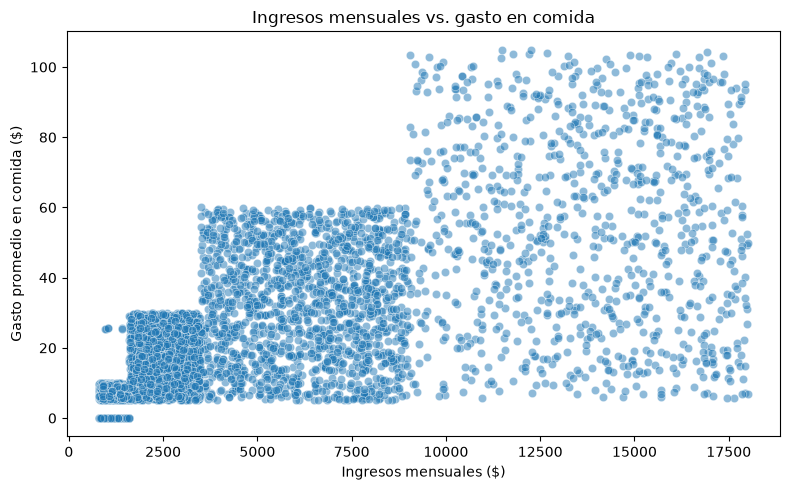

In [69]:
#1 ¿Existe relación entre los ingresos y el gasto en comida?
#Para responde esta pregunta usaremos un gráfico de dispersión para visualizar la relación entre los ingresos mensuales y el gasto promedio en comida de los clientes.
# Explorar la relación entre ingresos mensuales y gasto en comida
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_chicago, x='ingresos_mensuales',
                y='promedio_gasto_comida', alpha=0.5)

plt.title('Ingresos mensuales vs. gasto en comida')
plt.xlabel('Ingresos mensuales ($)')
plt.ylabel('Gasto promedio en comida ($)')
plt.tight_layout()
plt.show()
#La gráfica muestra una relación positiva entre los ingresos mensuales y el gasto promedio en comida.

In [70]:
# Calcula la correlación entre los ingresos mensuales y el gasto promedio en comida
correlacion = df_chicago["ingresos_mensuales"].corr(
    df_chicago["promedio_gasto_comida"]
)

print(f"Coeficiente de correlación: {correlacion:.3f}")

Coeficiente de correlación: 0.675


El coeficiente de correlación de Pearson es de **0,675**, lo que indica una asociación lineal positiva entre los ingresos mensuales y el gasto promedio en comida. En general, los clientes con mayores ingresos tienden a presentar un mayor gasto en comida. Sin embargo, existe variabilidad entre los datos, por lo que los ingresos no explican por sí solos el comportamiento del gasto. Esta asociación no implica causalidad.

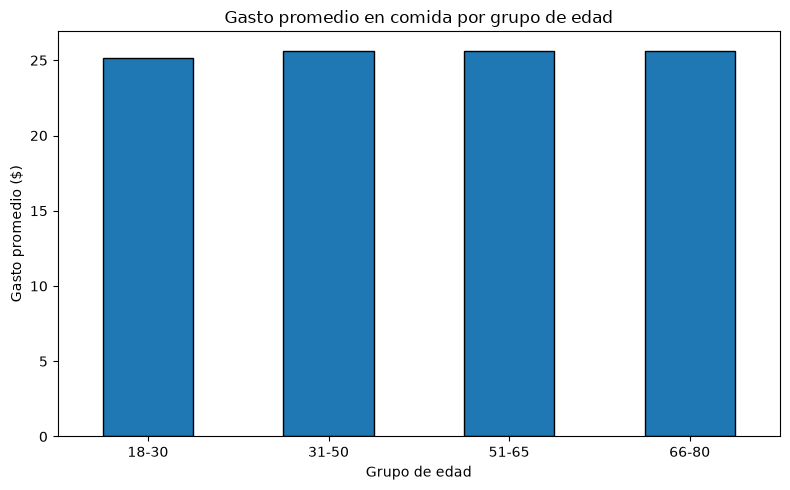

In [71]:
#2 ¿Cómo varía el gasto promedio según el grupo de edad?
#En este caso vamos a usar un gráfico de barras para comparar el gasto promedio en comida entre los diferentes grupos de edad.
# Comparar el gasto promedio entre grupos de edad
gasto_edad = df_chicago.groupby('grupo_edad')['promedio_gasto_comida'].mean().sort_index()

gasto_edad.plot(kind='bar', figsize=(8, 5), edgecolor='black')
plt.title('Gasto promedio en comida por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Gasto promedio ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

El gasto promedio en comida es relativamente similar entre los cuatro grupos de edad. El grupo de 18–30 años presenta un promedio ligeramente inferior, mientras que los demás grupos muestran valores cercanos a $25,5. Por tanto, en estos datos no se observan diferencias importantes en el gasto promedio según la edad.


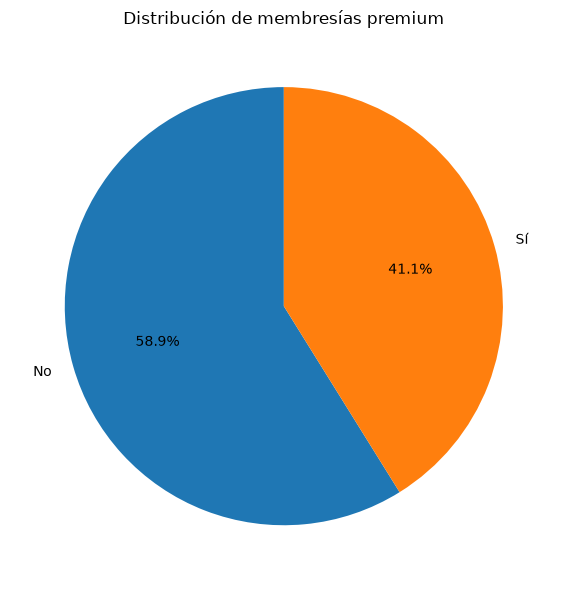

In [72]:
#3 ¿Qué proporción de clientes tiene membresía premium?
#En este caso vamos a usar un gráfico circular para visualizar la proporción de clientes con membresía premium y sin ella.
# Mostrar la proporción de clientes con y sin membresía premium
membresia = df_chicago['membresia_premium'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(membresia, labels=membresia.index, autopct='%1.1f%%',
        startangle=90)
plt.title('Distribución de membresías premium')
plt.tight_layout()
plt.show()

El 41,1 % de los clientes cuenta con una membresía premium, mientras que el 58,9 % no dispone de ella. Estos resultados muestran que la mayoría de los clientes no está afiliada al programa premium. Esta información podría servir como punto de partida para investigar qué factores influyen en la afiliación y qué estrategias podrían incentivar nuevas membresías.

In [77]:
#4 ¿Los clientes que visitan con mayor frecuencia gastan más en comida?
# Calcula el gasto promedio para cada frecuencia de visitas
df_frecuencia = df_chicago.groupby("frecuencia_visita").agg(
    cantidad_clientes=("id_persona", "count"),
    gasto_promedio=("promedio_gasto_comida", "mean")
).reset_index()

df_frecuencia.round(2)

,frecuencia_visita,cantidad_clientes,gasto_promedio
0,0,261,0.00
1,1,273,7.59
2,2,649,13.09
3,3,715,13.52
4,4,1207,25.58
5,5,1059,28.89
6,6,642,36.64
7,7,164,53.76
8,8,124,55.82
9,9,141,53.82


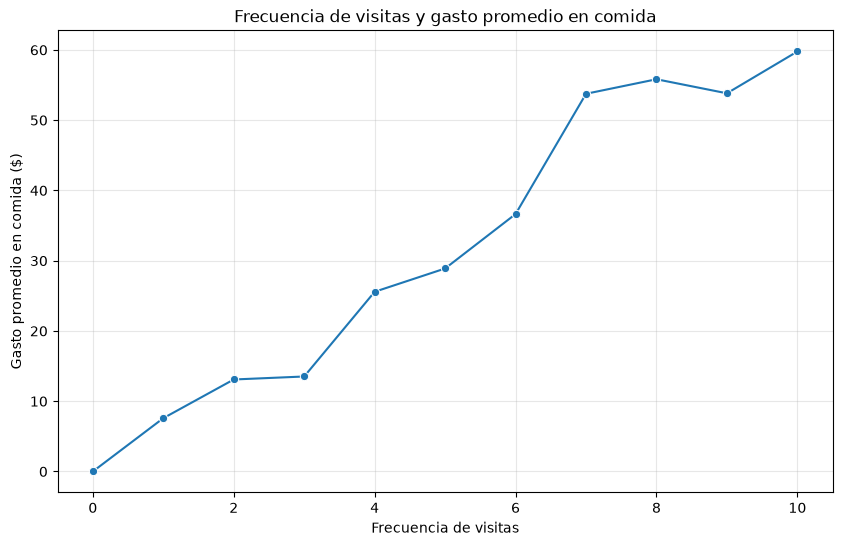

In [78]:
#Representa la relación entre frecuencia de visitas y gasto promedio

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df_frecuencia,
    x="frecuencia_visita",
    y="gasto_promedio",
    marker="o"
)

plt.title("Frecuencia de visitas y gasto promedio en comida")
plt.xlabel("Frecuencia de visitas")
plt.ylabel("Gasto promedio en comida ($)")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# 5 ¿Cómo se relacionan la frecuencia de visitas, el gasto promedio y el grupo de ingresos?
# Calcula el gasto promedio según la frecuencia de visitas y el grupo de ingresos
df_multivariado = df_chicago.groupby(
    ["frecuencia_visita", "grupo_ingresos"]
)["promedio_gasto_comida"].mean().reset_index()

df_multivariado.head(10)

,frecuencia_visita,grupo_ingresos,promedio_gasto_comida
0,0,Bajo,0.000000
1,1,Bajo,7.587326
2,2,Bajo,13.094561
3,3,Bajo,13.521524
4,4,Bajo,19.064000
5,4,Medio,33.130905
6,4,Alto,60.741739
7,4,Muy alto,44.439259
8,5,Bajo,20.356636
9,5,Medio,32.843440


Análisis multivariado: ¿Cómo se relacionan la frecuencia de visitas, el gasto promedio en comida y el grupo de ingresos?

Para profundizar en la relación entre la frecuencia de visitas y el gasto promedio en comida, se incorpora el grupo de ingresos como una tercera variable de análisis.

Mediante un gráfico de líneas se comparará el comportamiento del gasto promedio según la frecuencia de visitas, diferenciando a los clientes por su grupo de ingresos.

Este análisis permitirá identificar si el comportamiento del gasto varía entre los segmentos económicos y si la frecuencia de visitas presenta una relación similar con el consumo en cada grupo.

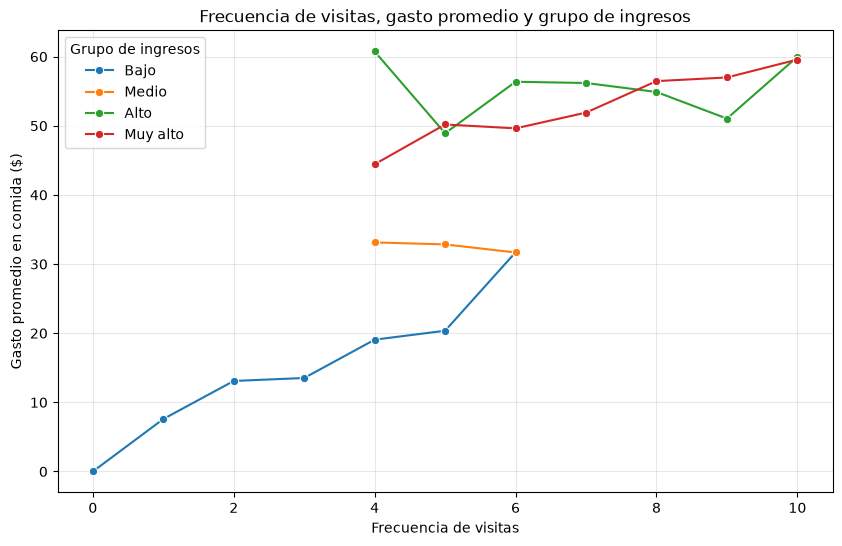

In [74]:
# Visualiza la relación entre frecuencia de visitas, gasto promedio y grupo de ingresos
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df_multivariado,
    x="frecuencia_visita",
    y="promedio_gasto_comida",
    hue="grupo_ingresos",
    marker="o"
)

plt.title("Frecuencia de visitas, gasto promedio y grupo de ingresos")
plt.xlabel("Frecuencia de visitas")
plt.ylabel("Gasto promedio en comida ($)")
plt.legend(title="Grupo de ingresos")
plt.grid(True, alpha=0.3)
plt.show()

Interpretación del análisis multivariado

El gráfico permite identificar diferencias en el comportamiento del gasto promedio en comida según la frecuencia de visitas y el grupo de ingresos.

Los principales resultados son:

* **Ingresos bajos:** presentan un incremento del gasto promedio conforme aumenta la frecuencia de visitas.
* **Ingresos medios:** mantienen un gasto promedio relativamente estable, entre $31 y $33.
* **Ingresos altos:** registran los mayores niveles de gasto en algunas frecuencias, aunque presentan fluctuaciones.
* **Ingresos muy altos:** muestran una tendencia general creciente, alcanzando aproximadamente $60 de gasto promedio.

En términos generales, los clientes de ingresos altos y muy altos presentan un mayor gasto promedio que los grupos de ingresos bajos y medios. Sin embargo, el comportamiento del gasto según la frecuencia de visitas varía entre los segmentos.

Estos resultados sugieren que el grupo de ingresos puede aportar información adicional para comprender los patrones de consumo y mejorar la segmentación comercial.

Es importante considerar que no existen observaciones para todas las frecuencias dentro de cada grupo, por lo que los resultados deben interpretarse con cautela y no implican una relación de causalidad.


In [79]:
#6 ¿Los clientes que visitan con mayor frecuencia gastan más en comida?
# Compara el gasto promedio, la mediana y la cantidad de clientes según su membresía
df_chicago.groupby("membresia_premium").agg(
    cantidad_clientes=("id_persona", "count"),
    gasto_promedio=("promedio_gasto_comida", "mean"),
    gasto_mediano=("promedio_gasto_comida", "median")
).round(2)

,cantidad_clientes,gasto_promedio,gasto_mediano
membresia_premium,,,
No,3169,15.73,11.24
Sí,2215,39.55,35.09


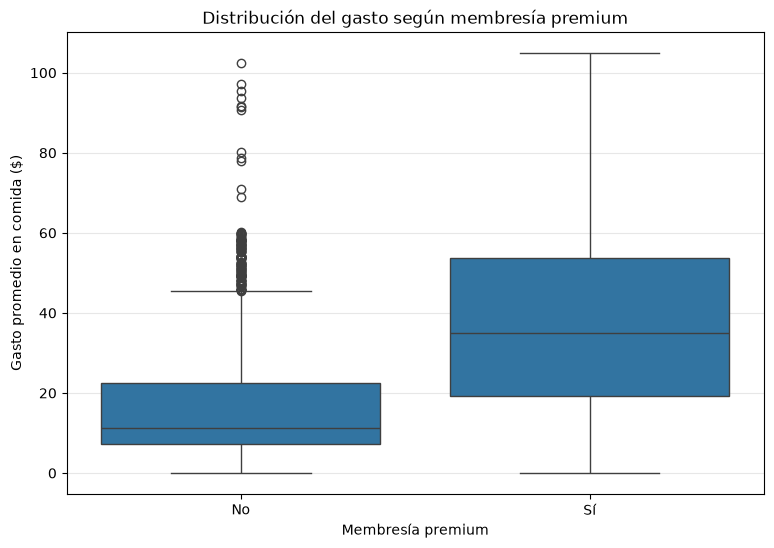

In [80]:
# Compara el gasto promedio, la mediana y la cantidad de clientes según su membresía
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_chicago,
    x="membresia_premium",
    y="promedio_gasto_comida"
)

plt.title("Distribución del gasto según membresía premium")
plt.xlabel("Membresía premium")
plt.ylabel("Gasto promedio en comida ($)")
plt.grid(axis="y", alpha=0.3)
plt.show()

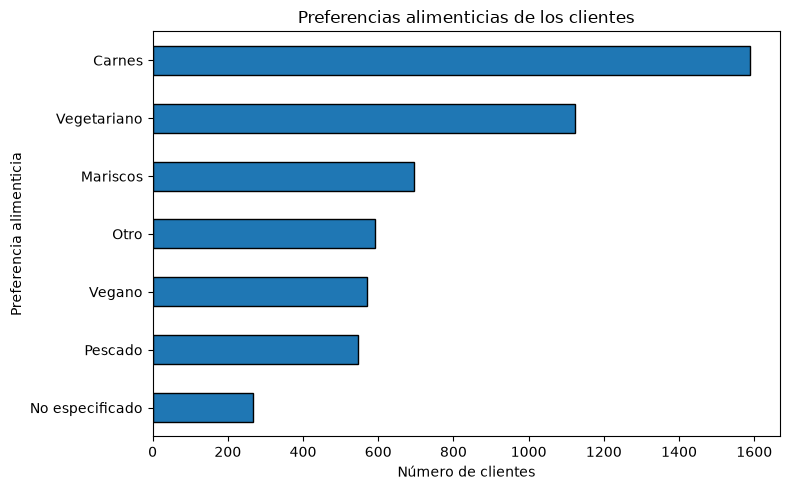

In [ ]:
#7 ¿Cuáles son las preferencias alimenticias más frecuentes?
#Para esta pregunta vamos a utlizar el gráfico de barras horizontales
# Contar y ordenar las preferencias alimenticias de los clientes
preferencias = df_chicago['preferencias_alimenticias'].value_counts().sort_values()

preferencias.plot(kind='barh', figsize=(8, 5), edgecolor='black')
plt.title('Preferencias alimenticias de los clientes')
plt.xlabel('Número de clientes')
plt.ylabel('Preferencia alimenticia')
plt.tight_layout()
plt.show()

Existe una mayor preferencia por alimentos basados en carnes. Sin embargo, también se observa una demanda importante de opciones vegetarianas y otras alternativas alimenticias.

Esto evidencia que la oferta gastronómica debe considerar distintos patrones de consumo y no concentrarse exclusivamente en una categoría.

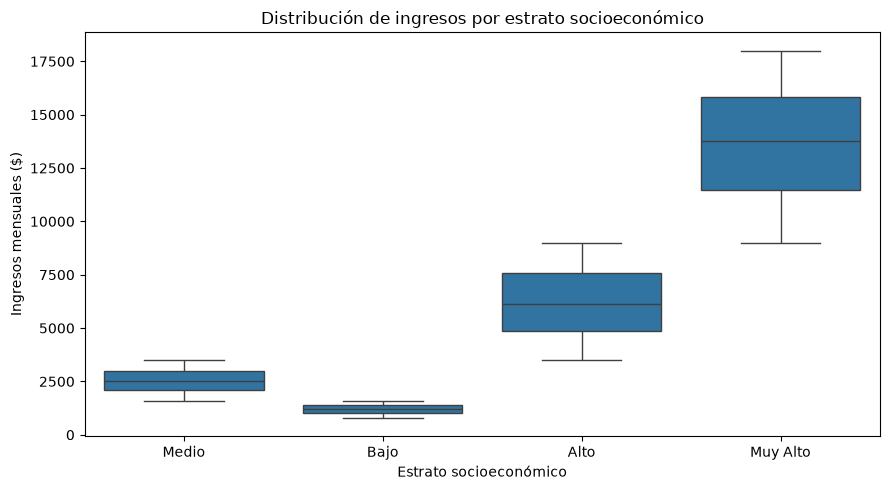

In [ ]:
#8 ¿Cómo se distribuyen los ingresos entre los estratos socioeconómicos?
#En esta pregunta usamos un gráfico boxplot
# Comparar la distribución de ingresos mensuales por estrato socioeconómico
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_chicago, x='estrato_socioeconomico',
            y='ingresos_mensuales')

plt.title('Distribución de ingresos por estrato socioeconómico')
plt.xlabel('Estrato socioeconómico')
plt.ylabel('Ingresos mensuales ($)')
plt.tight_layout()
plt.show()

Se observa una relación positiva entre el estrato socioeconómico y el nivel de ingresos: a medida que aumenta el estrato, también aumenta el ingreso mensual.

Además, los estratos alto y muy alto presentan una mayor variabilidad de ingresos que los estratos bajo y medio. Esto indica que existen diferencias económicas importantes incluso dentro de un mismo estrato.

El estrato socioeconómico permite distinguir grupos con niveles de ingresos claramente diferenciados, por lo que puede ser una variable útil para la segmentación comercial.

Análisis multivariado: frecuencia de visitas, gasto e ingresos

Este análisis busca identificar cómo se relaciona el gasto promedio en comida con la frecuencia de visitas, considerando también el grupo de ingresos de los clientes. De esta manera, podremos observar si el comportamiento de gasto varía entre los distintos segmentos económicos.

### Elaborar recomendaciones basadas en los hallazgos.

A partir de los resultados obtenidos en el análisis exploratorio de datos, se plantearán recomendaciones orientadas a mejorar la segmentación de clientes y apoyar la toma de decisiones comerciales.

Las propuestas se fundamentarán en los patrones observados en los ingresos, el gasto promedio en comida, los grupos de edad y la afiliación a membresías premium. Las recomendaciones deberán ser concretas, viables y susceptibles de evaluación mediante indicadores.

In [ ]:
#Comprobamos qué grupos de clientes existen realmente.
#Resumen los ingresos y el gasto promedio según los grupos de ingresos
df_chicago.groupby("grupo_ingresos").agg(
    cantidad_clientes=("id_persona", "count"),
    ingreso_promedio=("ingresos_mensuales", "mean"),
    gasto_promedio=("promedio_gasto_comida", "mean")
).round(2)

In [ ]:
#Vamos a calcular el procentaje para poder priorizar los segmentos.
# Calcula el porcentaje de clientes que pertenece a cada grupo de ingresos
(df_chicago["grupo_ingresos"].value_counts(normalize=True) * 100).round(2)

### Recomendación 1: Estrategias comerciales por segmento de ingresos

El 60,01 % de los clientes pertenece al grupo de ingresos bajos y registra un gasto promedio en comida de $14,67. Por su peso en la base de clientes, se recomienda evaluar promociones económicas, descuentos y menús combinados para este segmento.

Para los clientes de ingresos medios, altos y muy altos, se pueden probar ofertas diferenciadas según sus patrones de gasto. En particular, el grupo de ingresos muy altos presenta un gasto promedio de $53,39, ligeramente inferior a los $54,91 del grupo de ingresos altos.

Se recomienda medir los resultados de estas estrategias mediante indicadores como el gasto promedio, la frecuencia de compra y la tasa de respuesta a las promociones antes de implementarlas de forma generalizada.

### Recomendación 2: Evaluar la segmentación por edad

Los resultados muestran que el gasto promedio en comida es similar entre los distintos grupos de edad. Por ello, no se recomienda priorizar la edad como criterio principal para diferenciar promociones.

En su lugar, se propone evaluar variables como los ingresos, la frecuencia de visitas y las preferencias alimenticias para identificar segmentos con comportamientos de consumo diferentes.

### Recomendación 3: Fortalecer la membresía premium

El 41,1 % de los clientes cuenta con una membresía premium. Se recomienda ofrecer a estos clientes descuentos y promociones exclusivas para incentivar la frecuencia de compra y mantener su fidelidad.

Para los clientes sin membresía, se propone establecer una meta de consumo acumulado que les permita acceder a la inscripción o a beneficios iniciales de la membresía. Esto podría incentivar nuevas compras y aumentar la cantidad de clientes afiliados.

Se recomienda evaluar la estrategia mediante el crecimiento de afiliaciones, la frecuencia de compra y el gasto promedio de los miembros.
